In [11]:
#라이브러리 및 실행환경 설정

import torch
import torch.nn as nn               # 신경망 계층 구현
import matplotlib.pyplot as plt     # 이미지 및 그래프 시각화

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 실험 재현성을 위한 난수 시드
torch.manual_seed(42)

# CPU / GPU 설정
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [12]:
# MNIST 데이터셋 불러오기


transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Test:", len(test_dataset))


Train: 60000
Test: 10000


In [13]:

def add_noise(images, noise_level=0.3):
    noise = torch.randn_like(images) * noise_level

    noisy_images = images + noise

    return torch.clamp(noisy_images, 0.0, 1.0)


In [14]:

class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: 이미지의 특징을 추출하고 압축
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Decoder: 압축된 특징을 이미지로 복원
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                32, 16, kernel_size=2, stride=2
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                16, 1, kernel_size=2, stride=2
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


model = DenoisingAutoencoder().to(device)

print(model)


DenoisingAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(32, 16, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
    (3): Sigmoid()
  )
)


In [15]:

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10
noise_level = 0.3


In [16]:

train_losses = []

for epoch in range(epochs):
    model.train()

    total_loss = 0.0

    for images, _ in train_loader:
        # 원본 이미지를 GPU/CPU로 이동
        clean_images = images.to(device)

        # 노이즈 추가
        noisy_images = add_noise(clean_images, noise_level)     # 원본 이미지에 노이즈를 추가

        # 이전 기울기 초기화
        optimizer.zero_grad()

        # 노이즈 이미지 복원
        outputs = model(noisy_images)                           # 노이즈가 포함된 이미지를 모델에 입력

        # 복원 이미지와 원본 이미지 비교
        loss = criterion(outputs, clean_images)                 # 복원된 이미지와 원본 이미지 간의 손실 계산

        # 역전파
        loss.backward()

        # 가중치 업데이트
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    avg_loss = total_loss / len(train_dataset)
    train_losses.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )


Epoch [1/10] Loss: 0.038258
Epoch [2/10] Loss: 0.009882
Epoch [3/10] Loss: 0.008802
Epoch [4/10] Loss: 0.008346
Epoch [5/10] Loss: 0.008055
Epoch [6/10] Loss: 0.007828
Epoch [7/10] Loss: 0.007651
Epoch [8/10] Loss: 0.007520
Epoch [9/10] Loss: 0.007412
Epoch [10/10] Loss: 0.007327


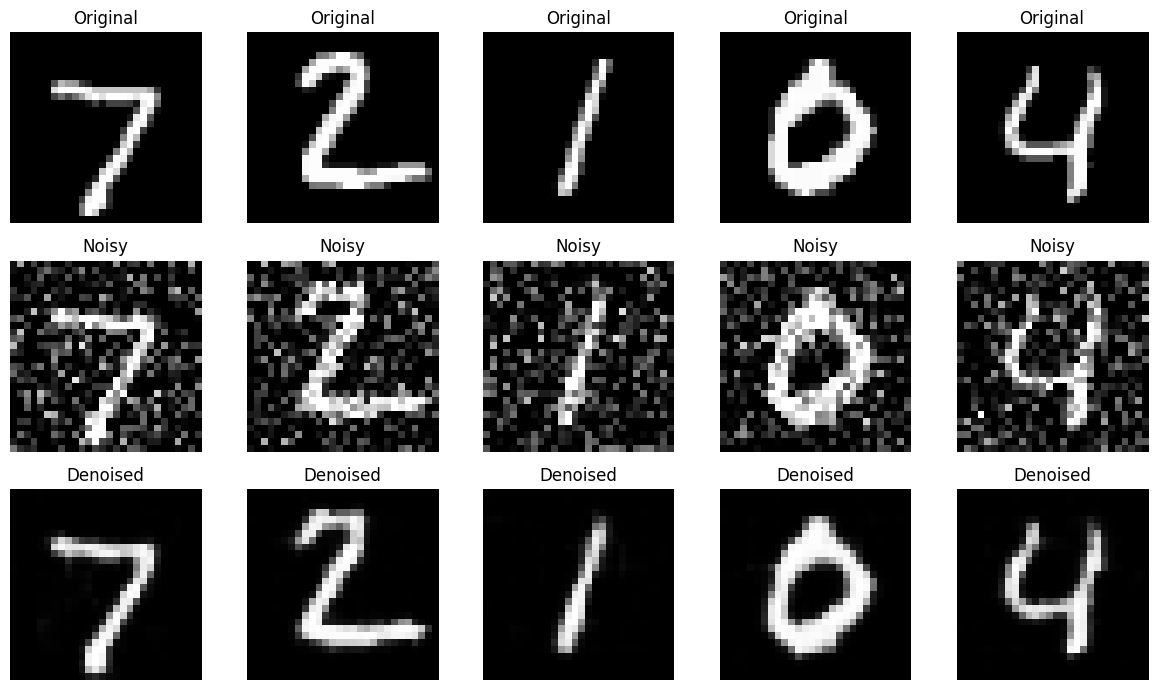

In [17]:

model.eval()

# 테스트 데이터 5장 가져오기
clean_images = torch.stack([
    test_dataset[i][0] for i in range(5)
]).to(device)

# 노이즈 추가
torch.manual_seed(42)
noisy_images = add_noise(clean_images, 0.3)

# 학습된 모델로 복원
with torch.no_grad():
    denoised_images = model(noisy_images)

# 시각화를 위해 CPU로 이동
clean_images = clean_images.cpu()
noisy_images = noisy_images.cpu()
denoised_images = denoised_images.cpu()

fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i in range(5):
    axes[0, i].imshow(
        clean_images[i].squeeze(), cmap="gray",
        vmin=0, vmax=1
    )
    axes[0, i].set_title("Original")

    axes[1, i].imshow(
        noisy_images[i].squeeze(), cmap="gray",
        vmin=0, vmax=1
    )
    axes[1, i].set_title("Noisy")

    axes[2, i].imshow(
        denoised_images[i].squeeze(), cmap="gray",
        vmin=0, vmax=1
    )
    axes[2, i].set_title("Denoised")

    for row in range(3):
        axes[row, i].axis("off")

plt.tight_layout()
plt.show()


In [18]:

import numpy as np
from skimage.metrics import structural_similarity

model.eval()

noise_level = 0.3

noisy_mse = []
denoised_mse = []

noisy_psnr = []
denoised_psnr = []

noisy_ssim = []
denoised_ssim = []

torch.manual_seed(42)

with torch.no_grad():
    for images, _ in test_loader:

        # 원본 이미지
        clean_images = images.to(device)

        # 노이즈 추가 (CPU에서 생성 후 이동)
        noisy_images = add_noise(images, noise_level).to(device)

        # Denoising 모델로 이미지 복원
        restored_images = model(noisy_images)

        for clean, noisy, restored in zip(
            clean_images, noisy_images, restored_images
        ):
            clean = clean.squeeze().cpu().numpy()
            noisy = noisy.squeeze().cpu().numpy()
            restored = restored.squeeze().cpu().numpy()

            # MSE
            mse_before = np.mean((clean - noisy) ** 2)
            mse_after = np.mean((clean - restored) ** 2)

            noisy_mse.append(mse_before)
            denoised_mse.append(mse_after)

            # PSNR
            noisy_psnr.append(
                10 * np.log10(1.0 / max(mse_before, 1e-12))
            )
            denoised_psnr.append(
                10 * np.log10(1.0 / max(mse_after, 1e-12))
            )

            # SSIM
            noisy_ssim.append(
                structural_similarity(clean, noisy, data_range=1.0)
            )
            denoised_ssim.append(
                structural_similarity(clean, restored, data_range=1.0)
            )

# MSE = 원본 이미지와의 픽셀 오차
# PSNR = 원본 대비 영상 복원 품질
# SSIM = 이미지의 구조적 유사도 

print("=== Noise Level: 0.3 ===")
print(f"MSE  : {np.mean(noisy_mse):.6f} → {np.mean(denoised_mse):.6f}")
print(f"PSNR : {np.mean(noisy_psnr):.2f} → {np.mean(denoised_psnr):.2f} dB")
print(f"SSIM : {np.mean(noisy_ssim):.4f} → {np.mean(denoised_ssim):.4f}")


=== Noise Level: 0.3 ===
MSE  : 0.046561 → 0.007141
PSNR : 13.33 → 21.80 dB
SSIM : 0.5282 → 0.8935


In [22]:
state_dict = torch.load(
    "models/mnist_cnn.pth",
    map_location=device,
    weights_only=True
)

for name, weights in state_dict.items():
    print(name, tuple(weights.shape))

conv.1.weight (16, 1, 3, 3)
conv.1.bias (16,)
conv.3.weight (32, 16, 3, 3)
conv.3.bias (32,)
fc.weight (10, 1568)
fc.bias (10,)


In [24]:
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score

# 기존 MNIST 분류 모델
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.MaxPool2d(1),
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(4)
        )

        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.conv(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


# CNN 모델 생성
classifier = CNN().to(device)

# 학습된 가중치 불러오기
classifier.load_state_dict(
    torch.load(
        "models/mnist_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

classifier.eval()

print("CNN 모델 로드 완료")

# 기존 CNN 정확도 검증
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = classifier(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"기존 CNN Accuracy: {accuracy:.2f}%")

/home/junea/.local/lib/python3.8/site-packages/sklearn/utils/multiclass.py:13: DeprecationWarning: Please use `spmatrix` from the `scipy.sparse` namespace, the `scipy.sparse.base` namespace is deprecated.
  from scipy.sparse.base import spmatrix


CNN 모델 로드 완료
기존 CNN Accuracy: 95.16%


In [25]:
from sklearn.metrics import accuracy_score, f1_score
import torch

# 두 모델 모두 평가 모드
model.eval()       # Denoising Autoencoder
classifier.eval()  # 기존 CNN 분류 모델

noise_level = 0.3

all_labels = []
clean_predictions = []
noisy_predictions = []
denoised_predictions = []

# 기존 노이즈 실험과 동일한 난수 시드
torch.manual_seed(42)

with torch.no_grad():
    for images, labels in test_loader:
        clean_images = images.to(device)

        # 노이즈 이미지 생성
        noisy_images = add_noise(images, noise_level).to(device)

        # Denoising 모델로 복원
        denoised_images = model(noisy_images)

        # 각각 CNN으로 분류
        clean_pred = classifier(clean_images).argmax(dim=1)
        noisy_pred = classifier(noisy_images).argmax(dim=1)
        denoised_pred = classifier(denoised_images).argmax(dim=1)

        all_labels.extend(labels.tolist())
        clean_predictions.extend(clean_pred.cpu().tolist())
        noisy_predictions.extend(noisy_pred.cpu().tolist())
        denoised_predictions.extend(denoised_pred.cpu().tolist())

# 결과 비교
results_classification = {}

for name, predictions in [
    ("Original", clean_predictions),
    ("Noisy", noisy_predictions),
    ("Denoised", denoised_predictions)
]:
    accuracy = accuracy_score(all_labels, predictions)
    f1 = f1_score(all_labels, predictions, average="macro")

    results_classification[name] = {
        "accuracy": accuracy,
        "f1": f1
    }

    print(
        f"{name:10s} | "
        f"Accuracy: {accuracy * 100:.2f}% | "
        f"Macro F1: {f1 * 100:.2f}%"
    )

# Denoising 적용에 따른 정확도 변화
improvement = (
    results_classification["Denoised"]["accuracy"]
    - results_classification["Noisy"]["accuracy"]
) * 100

print(f"\nDenoising 정확도 변화: {improvement:+.2f}%p")

Original   | Accuracy: 95.16% | Macro F1: 95.20%
Noisy      | Accuracy: 77.07% | Macro F1: 75.41%
Denoised   | Accuracy: 94.11% | Macro F1: 94.17%

Denoising 정확도 변화: +17.04%p


In [26]:

import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

noise_levels = [0.1, 0.2, 0.3, 0.5]
experiment_results = []

model.eval()
classifier.eval()

for level in noise_levels:
    labels_all = []
    noisy_preds = []
    denoised_preds = []

    mse_before = []
    mse_after = []
    psnr_before = []
    psnr_after = []
    ssim_before = []
    ssim_after = []

    # 매 노이즈 강도마다 난수 생성 순서 고정
    torch.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:
            clean = images.to(device)
            noisy = add_noise(images, level).to(device)
            denoised = model(noisy)

            # CNN 숫자 분류
            pred_noisy = classifier(noisy).argmax(dim=1)
            pred_denoised = classifier(denoised).argmax(dim=1)

            labels_all.extend(labels.tolist())
            noisy_preds.extend(pred_noisy.cpu().tolist())
            denoised_preds.extend(pred_denoised.cpu().tolist())

            # 이미지 복원 품질
            clean_np = clean.cpu().numpy()
            noisy_np = noisy.cpu().numpy()
            denoised_np = denoised.cpu().numpy()

            for c, n, d in zip(clean_np, noisy_np, denoised_np):
                c = c.squeeze()
                n = n.squeeze()
                d = d.squeeze()

                mse_before.append(np.mean((c - n) ** 2))
                mse_after.append(np.mean((c - d) ** 2))

                psnr_before.append(
                    peak_signal_noise_ratio(c, n, data_range=1.0)
                )
                psnr_after.append(
                    peak_signal_noise_ratio(c, d, data_range=1.0)
                )

                ssim_before.append(
                    structural_similarity(c, n, data_range=1.0)
                )
                ssim_after.append(
                    structural_similarity(c, d, data_range=1.0)
                )

    result = {
        "noise": level,
        "accuracy_before": accuracy_score(labels_all, noisy_preds) * 100,
        "accuracy_after": accuracy_score(labels_all, denoised_preds) * 100,
        "f1_before": f1_score(labels_all, noisy_preds, average="macro") * 100,
        "f1_after": f1_score(labels_all, denoised_preds, average="macro") * 100,
        "mse_before": float(np.mean(mse_before)),
        "mse_after": float(np.mean(mse_after)),
        "psnr_before": float(np.mean(psnr_before)),
        "psnr_after": float(np.mean(psnr_after)),
        "ssim_before": float(np.mean(ssim_before)),
        "ssim_after": float(np.mean(ssim_after))
    }

    experiment_results.append(result)

    print(f"\n=== Noise Level: {level} ===")
    print(f"Accuracy : {result['accuracy_before']:.2f}% → {result['accuracy_after']:.2f}%")
    print(f"Macro F1 : {result['f1_before']:.2f}% → {result['f1_after']:.2f}%")
    print(f"MSE      : {result['mse_before']:.6f} → {result['mse_after']:.6f}")
    print(f"PSNR     : {result['psnr_before']:.2f} → {result['psnr_after']:.2f} dB")
    print(f"SSIM     : {result['ssim_before']:.4f} → {result['ssim_after']:.4f}")



=== Noise Level: 0.1 ===
Accuracy : 94.87% → 94.97%
Macro F1 : 94.94% → 95.02%
MSE      : 0.005424 → 0.003938
PSNR     : 22.67 → 24.60 dB
SSIM     : 0.6969 → 0.9423

=== Noise Level: 0.2 ===
Accuracy : 91.28% → 94.67%
Macro F1 : 91.29% → 94.73%
MSE      : 0.021176 → 0.005030
PSNR     : 16.75 → 23.42 dB
SSIM     : 0.6127 → 0.9309

=== Noise Level: 0.3 ===
Accuracy : 77.07% → 94.11%
Macro F1 : 75.41% → 94.17%
MSE      : 0.046561 → 0.007141
PSNR     : 13.33 → 21.80 dB
SSIM     : 0.5282 → 0.8935

=== Noise Level: 0.5 ===
Accuracy : 43.02% → 84.32%
Macro F1 : 39.29% → 84.38%
MSE      : 0.115452 → 0.019681
PSNR     : 9.39 → 17.23 dB
SSIM     : 0.3754 → 0.6487


/home/junea/.local/lib/python3.8/site-packages/sklearn/metrics/classification.py:1134: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no predicted samples.
  precision = _prf_divide(tp_sum, pred_sum,


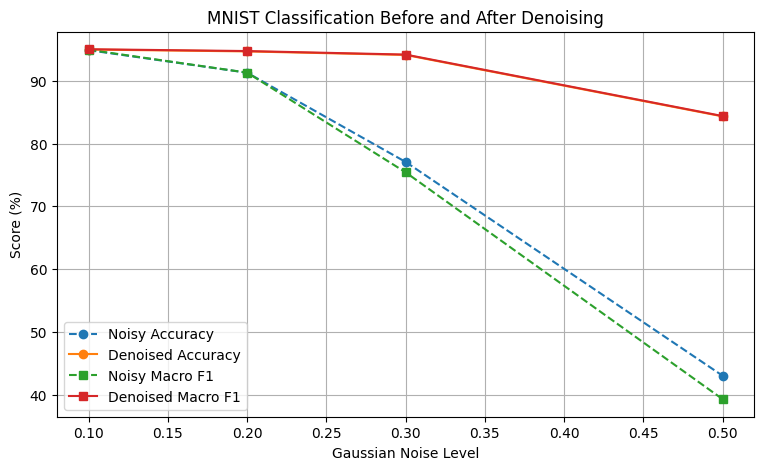

In [27]:

import matplotlib.pyplot as plt

levels = [r["noise"] for r in experiment_results]

acc_before = [r["accuracy_before"] for r in experiment_results]
acc_after = [r["accuracy_after"] for r in experiment_results]

f1_before = [r["f1_before"] for r in experiment_results]
f1_after = [r["f1_after"] for r in experiment_results]

plt.figure(figsize=(9, 5))

plt.plot(levels, acc_before, "o--", label="Noisy Accuracy")
plt.plot(levels, acc_after, "o-", label="Denoised Accuracy")

plt.plot(levels, f1_before, "s--", label="Noisy Macro F1")
plt.plot(levels, f1_after, "s-", label="Denoised Macro F1")

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Score (%)")
plt.title("MNIST Classification Before and After Denoising")

plt.legend()
plt.grid(True)
plt.show()


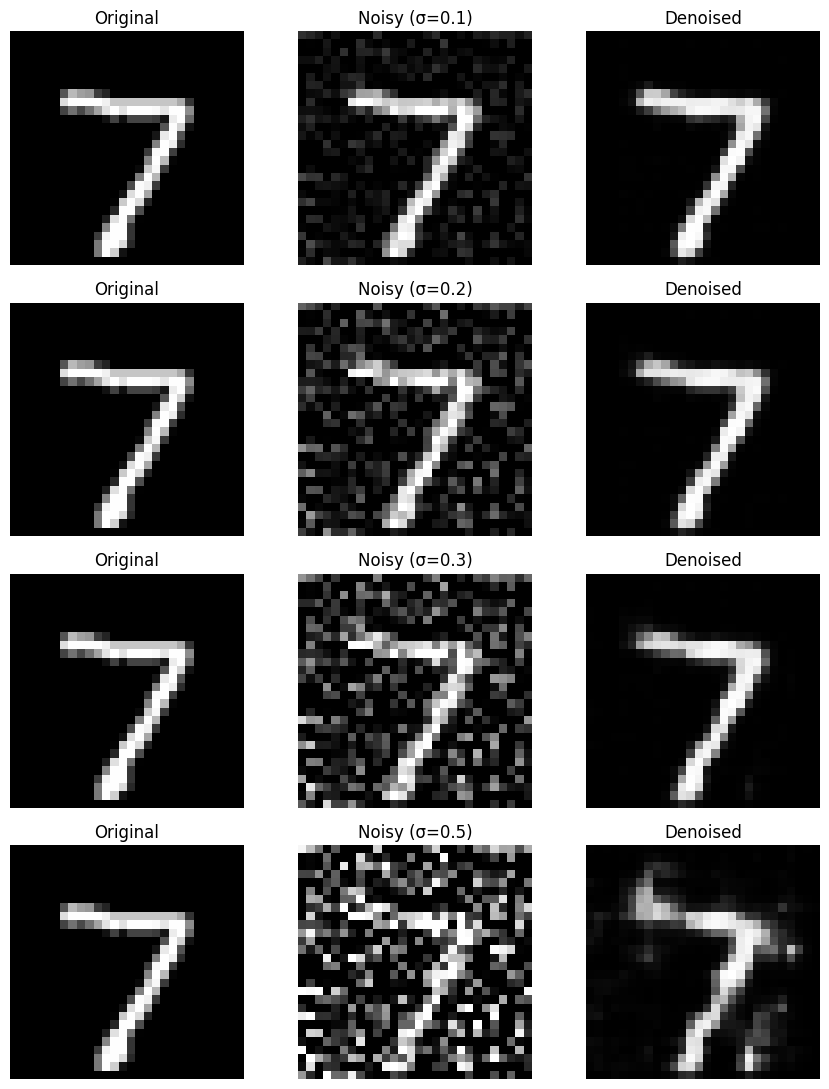

In [28]:

noise_levels = [0.1, 0.2, 0.3, 0.5]

# 테스트 데이터 첫 번째 이미지
image, label = test_dataset[0]
image = image.unsqueeze(0)

fig, axes = plt.subplots(
    len(noise_levels), 3,
    figsize=(9, 11)
)

model.eval()
torch.manual_seed(42)

# 모든 강도에 동일한 노이즈 패턴 적용
base_noise = torch.randn_like(image)

with torch.no_grad():
    for i, level in enumerate(noise_levels):
        noisy = torch.clamp(
            image + base_noise * level,
            0.0, 1.0
        )

        denoised = model(
            noisy.to(device)
        ).cpu()

        images = [
            image,
            noisy,
            denoised
        ]

        titles = [
            "Original",
            f"Noisy (σ={level})",
            "Denoised"
        ]

        for j in range(3):
            axes[i, j].imshow(
                images[j].squeeze(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[i, j].set_title(titles[j])
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [29]:

import os
import torch

os.makedirs("models", exist_ok=True)

torch.save(
    model.state_dict(),
    "models/mnist_denoising.pth"
)

print("Denoising 모델 저장 완료")


Denoising 모델 저장 완료
